# BMI 500 - Week 7 - Homework

## HW3

### Part A

Polynomial SBP -> MSE: 0.29 | R2: 0.99 | AIC: -5.20 | BIC: -4.61
Sigmoid SBP    -> MSE: 0.22 | R2: 1.00 | AIC: -5.57 | BIC: -4.79


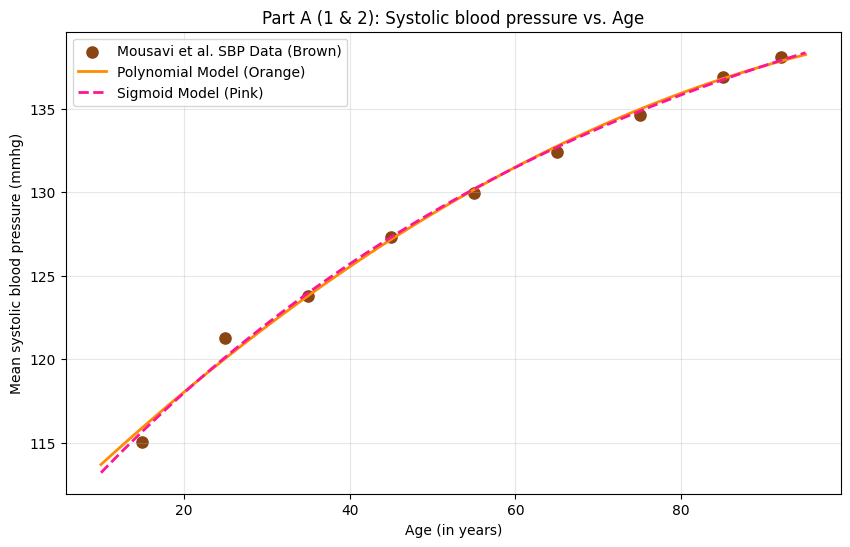

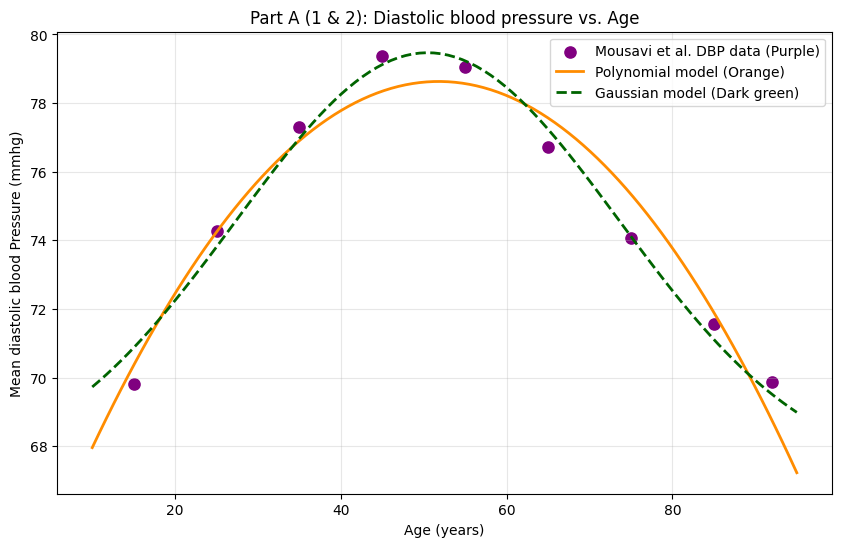

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from sklearn.metrics import mean_squared_error, r2_score

#Pooled age data
ages = np.array([15, 25, 35, 45, 55, 65, 75, 85, 92])
sbp_means = np.array([115.05, 121.27, 123.79, 127.32, 129.98, 132.42, 134.62, 136.89, 138.11])
dbp_means = np.array([69.80, 74.27, 77.31, 79.36, 79.05, 76.71, 74.06, 71.56, 69.86])

def polynomial_model(a, c1, c2, c3):
    return c1 * (a ** 2) + c2 * a + c3

def sbp_sigmoid(a, S0, delta_S, k, a0):
    return S0 + (delta_S / (1.0 + np.exp(-k * (a - a0))))

def dbp_gaussian(a, D0, delta_D, a_peak, sigma):
    return D0 + delta_D * np.exp(-((a - a_peak) ** 2) / (2 * (sigma ** 2)))

#Polynomial models
poly_sbp_coeffs = np.polyfit(ages, sbp_means, 2)
poly_dbp_coeffs = np.polyfit(ages, dbp_means, 2)

#Non-linear Models
p0_sbp = [110.0, 30.0, 0.08, 50.0]
popt_sbp, _ = curve_fit(sbp_sigmoid, ages, sbp_means, p0=p0_sbp, maxfev=10000)

p0_dbp = [68.0, 12.0, 45.0, 15.0]
popt_dbp, _ = curve_fit(dbp_gaussian, ages, dbp_means, p0=p0_dbp, maxfev=10000)

def compute_metrics(y_true, y_pred, n_params):
    n = len(y_true)
    mse = mean_squared_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    aic = n * np.log(mse) + 2 * n_params
    bic = n * np.log(mse) + n_params * np.log(n)
    return mse, r2, aic, bic
age_smooth = np.linspace(10, 95, 100)
pred_poly_sbp = polynomial_model(age_smooth, *poly_sbp_coeffs)
pred_sig_sbp = sbp_sigmoid(age_smooth, *popt_sbp)

pred_poly_dbp = polynomial_model(age_smooth, *poly_dbp_coeffs)
pred_gauss_dbp = dbp_gaussian(age_smooth, *popt_dbp)
mse_p_sbp, r2_p_sbp, aic_p_sbp, bic_p_sbp = compute_metrics(sbp_means, polynomial_model(ages, *poly_sbp_coeffs), 3)
mse_s_sbp, r2_s_sbp, aic_s_sbp, bic_s_sbp = compute_metrics(sbp_means, sbp_sigmoid(ages, *popt_sbp), 4)

print(f"Polynomial SBP -> MSE: {mse_p_sbp:.2f} | R2: {r2_p_sbp:.2f} | AIC: {aic_p_sbp:.2f} | BIC: {bic_p_sbp:.2f}")
print(f"Sigmoid SBP    -> MSE: {mse_s_sbp:.2f} | R2: {r2_s_sbp:.2f} | AIC: {aic_s_sbp:.2f} | BIC: {bic_s_sbp:.2f}")


plt.figure(figsize=(10, 6))
plt.scatter(ages, sbp_means, color='saddlebrown', label='Mousavi et al. SBP Data (Brown)', s=65)
plt.plot(age_smooth, pred_poly_sbp, color='darkorange', label='Polynomial Model (Orange)', linewidth=2)
plt.plot(age_smooth, pred_sig_sbp, color='deeppink', label='Sigmoid Model (Pink)', linewidth=2, linestyle='--')
plt.title('Part A (1 & 2): Systolic blood pressure vs. Age')
plt.xlabel('Age (in years)')
plt.ylabel('Mean systolic blood pressure (mmhg)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


# DBP Plot
plt.figure(figsize=(10, 6))
plt.scatter(ages, dbp_means, color='purple', label='Mousavi et al. DBP data (Purple)', s=65)
plt.plot(age_smooth, pred_poly_dbp, color='darkorange', label='Polynomial model (Orange)', linewidth=2)
plt.plot(age_smooth, pred_gauss_dbp, color='darkgreen', label='Gaussian model (Dark green)', linewidth=2, linestyle='--')
plt.title('Part A (1 & 2): Diastolic blood pressure vs. Age')
plt.xlabel('Age (years)')
plt.ylabel('Mean diastolic blood Pressure (mmhg)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()



###Part B

In [2]:
import matplotlib.pyplot as plt
np.random.seed(42)

def generate_bivariate_population(n_samples, mean_sbp, sd_sbp, mean_dbp, sd_dbp, rho, label):
    #mean vector and covariance matrix
    mean_vec = [mean_sbp, mean_dbp]
    cov_matrix = [
        [sd_sbp**2, rho * sd_sbp * sd_dbp],
        [rho * sd_sbp * sd_dbp, sd_dbp**2]
    ]
    #multivariate normal distribution samples
    data = np.random.multivariate_normal(mean_vec, cov_matrix, n_samples)
    labels = np.full((n_samples, 1), label)
    return np.hstack((data, labels))

def create_dataset(ratio_m_f, total_samples=60000):
    m_count = int(total_samples * (ratio_m_f[0] / 100.0))
    f_count = total_samples - m_count

    male_data = generate_bivariate_population(m_count, 133.0, 18.6, 78.8, 12.6, 0.45, label=1)
    female_data = generate_bivariate_population(f_count, 125.8, 19.0, 74.8, 12.4, 0.50, label=0)

    dataset = np.vstack((male_data, female_data))
    np.random.shuffle(dataset)
    return dataset[:, :2], dataset[:, 2]

# 90-10 training-evaluation dataset
X_90_10, y_90_10 = create_dataset((90, 10), total_samples=60000)
# 50-50 test set
X_test_bal, y_test_bal = create_dataset((50, 50), total_samples=10000)

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, confusion_matrix

X_train, X_val, y_train, y_val = train_test_split(X_90_10, y_90_10, test_size=0.3, random_state=42, stratify=y_90_10)

#Logistic Regression
clf = LogisticRegression()
clf.fit(X_train, y_train)

# Evaluation
y_pred = clf.predict(X_test_bal)
y_prob = clf.predict_proba(X_test_bal)[:, 1]

acc = accuracy_score(y_test_bal, y_pred)
f1 = f1_score(y_test_bal, y_pred)
auc = roc_auc_score(y_test_bal, y_prob)

print(f"Balanced test accuracy: {acc}")
print(f"Balanced test f1 Score: {f1}")
print(f"Balanced test AUC: {auc}")

Balanced test accuracy: 0.5
Balanced test f1 Score: 0.6666666666666666
Balanced test AUC: 0.6267773600000001


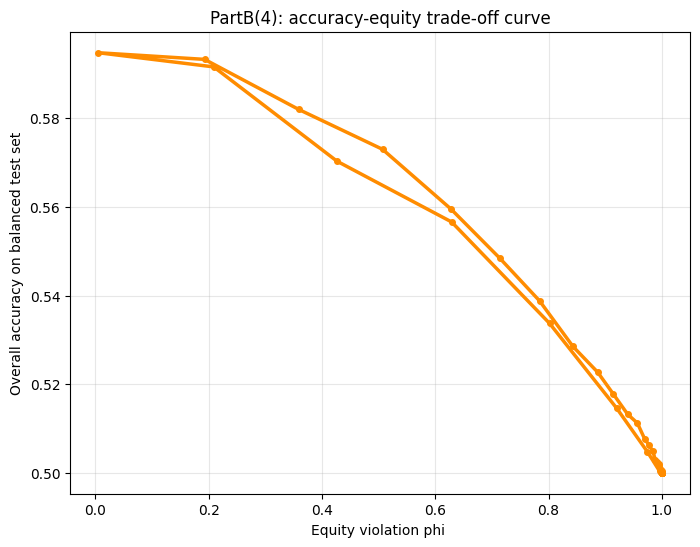

In [6]:
thresholds = np.linspace(0.0, 1.0, 101)
accuracies = []
phi_values = []
for th in thresholds:
    y_pred_th = (y_prob >= th).astype(int)
    acc_th = accuracy_score(y_test_bal, y_pred_th)
    cm = confusion_matrix(y_test_bal, y_pred_th, labels=[0, 1])
    if cm.shape == (2, 2):
        tn, fp, fn, tp = cm.ravel()
        recall_female = tn / (tn + fp) if (tn + fp) > 0 else 0
        recall_male = tp / (tp + fn) if (tp + fn) > 0 else 0

        phi = abs(recall_male - recall_female)
        accuracies.append(acc_th)
        phi_values.append(phi)

plt.figure(figsize=(8, 6))
plt.plot(phi_values, accuracies, color='darkorange', linewidth=2.5, marker='o', markersize=4)
plt.title('PartB(4): accuracy-equity trade-off curve')
plt.xlabel('Equity violation phi ')
plt.ylabel('Overall accuracy on balanced test set')
plt.grid(True, alpha=0.3)
plt.show()